# AML transaction monitoring — exploratory data analysis
Executed on the local IBM HI-Small synthetic dataset. Charts summarize observed
patterns, not evidence of real money laundering. Labels refer to the synthetic
dataset's ground truth.

All charts use the full CSV, with aggregation before plotting. Amounts are
separated by payment currency. This is retrospective EDA across the entire
dataset, including the held-out period; do not use these findings to retune the
evaluated model without a fresh holdout.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from aml_analytics.data import load_ibm_transactions

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data/raw/HI-Small_Trans.csv"
df = load_ibm_transactions(DATA)
con = duckdb.connect()
con.register("transactions", df)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def query(sql):
    return con.execute(sql).fetchdf()
print(f"Source: {DATA.name}")
print(f"Transactions: {len(df):,}")
print(f"Labelled laundering: {df.is_laundering.sum():,} ({df.is_laundering.mean():.4%})")
print(f"Dates: {df.timestamp.min()} to {df.timestamp.max()}")
print(f"Unique sending accounts: {df.sender_id.nunique():,}")
print(f"Unique receiving accounts: {df.receiver_id.nunique():,}")
print("Missing normalized values:", int(df.isna().sum().sum()))


Source: HI-Small_Trans.csv
Transactions: 5,078,345
Labelled laundering: 5,177 (0.1019%)
Dates: 2022-09-01 00:00:00 to 2022-09-18 16:18:00
Unique sending accounts: 496,999
Unique receiving accounts: 420,640
Missing normalized values: 0


## 1. Class imbalance
The counts explain why accuracy alone is misleading. The right panel makes the
rare positive class visible using a logarithmic count axis.


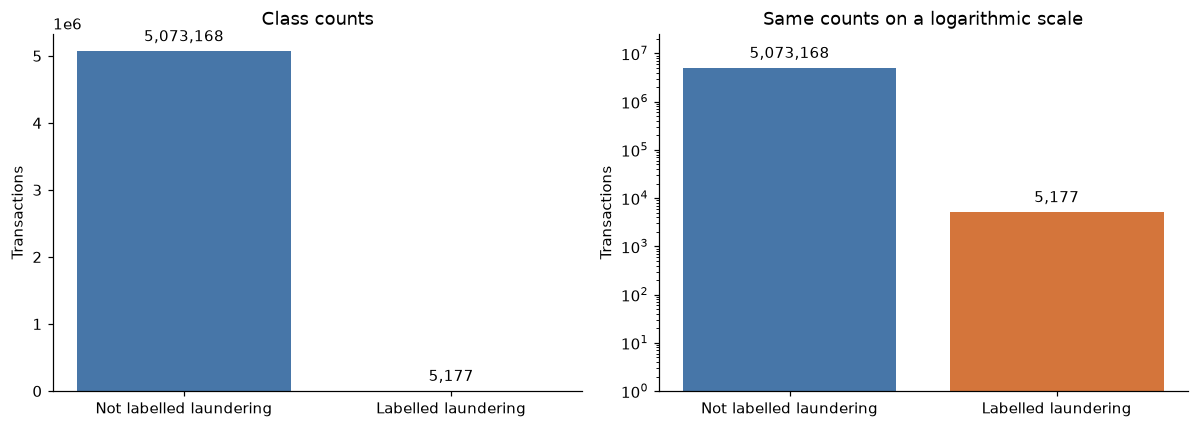

In [2]:
counts = df.is_laundering.value_counts().reindex([0, 1], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax in axes:
    bars = ax.bar(["Not labelled laundering", "Labelled laundering"], counts,
                  color=["#4776a8", "#d4753b"])
    ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
    ax.set_ylabel("Transactions")
axes[0].set_title("Class counts")
axes[1].set_yscale("log")
axes[1].set_ylim(1, counts.max()*5)
axes[1].set_title("Same counts on a logarithmic scale")
fig.tight_layout()
plt.show()


## 2. Daily volume and labelled rate
Compare volume with prevalence rather than treating a larger labelled count as a
higher risk rate. The first and last dates may be partial observation days.


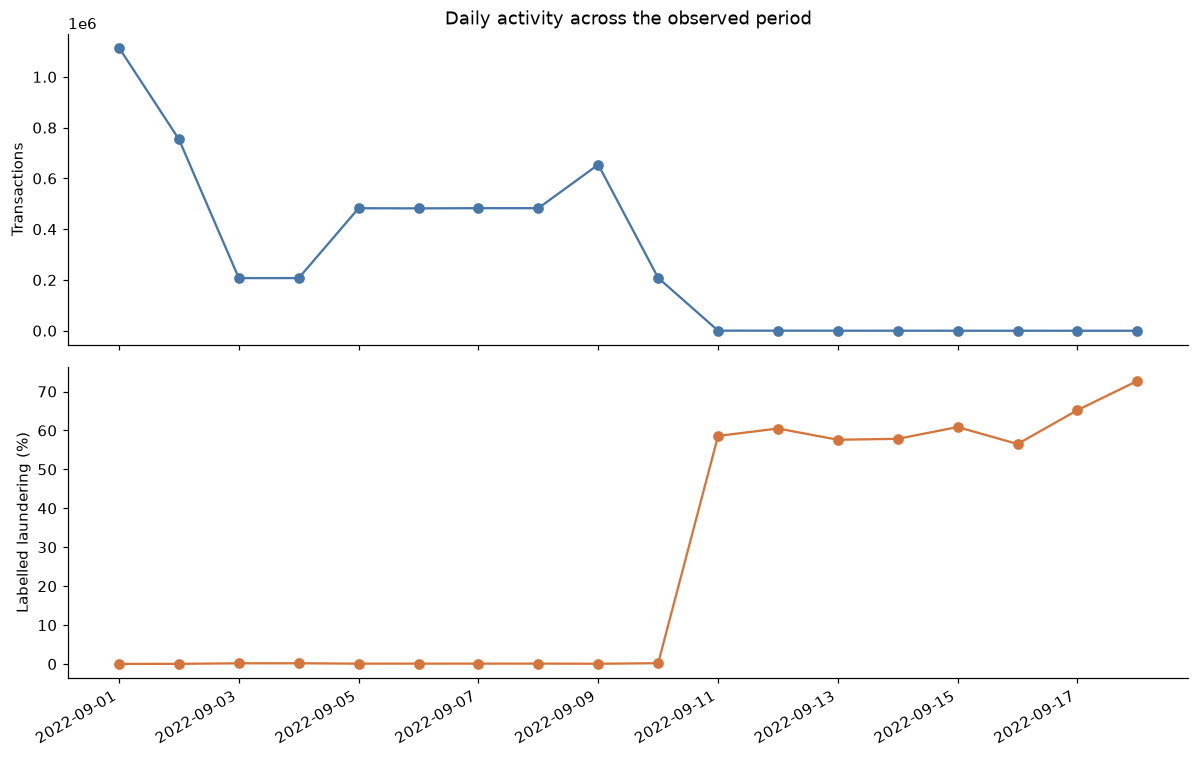

       day  transactions  labelled  labelled_pct
2022-09-01       1114921     322.0      0.028881
2022-09-02        754449     408.0      0.054079
2022-09-03        207382     391.0      0.188541
2022-09-04        207430     407.0      0.196211
2022-09-05        482650     471.0      0.097586
2022-09-06        482089     531.0      0.110146
2022-09-07        482751     497.0      0.102952
2022-09-08        482773     539.0      0.111647
2022-09-09        654467     514.0      0.078537
2022-09-10        208325     442.0      0.212168
2022-09-11           396     232.0     58.585859
2022-09-12           281     170.0     60.498221
2022-09-13           184     106.0     57.608696
2022-09-14           121      70.0     57.851240
2022-09-15            46      28.0     60.869565
2022-09-16            46      26.0     56.521739
2022-09-17            23      15.0     65.217391
2022-09-18            11       8.0     72.727273


In [3]:
daily = query('''
SELECT CAST(timestamp AS DATE) AS day, COUNT(*) AS transactions,
       SUM(is_laundering) AS labelled, AVG(is_laundering)*100 AS labelled_pct
FROM transactions GROUP BY 1 ORDER BY 1
''')
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(daily.day, daily.transactions, marker="o", color="#4776a8")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Daily activity across the observed period")
axes[1].plot(daily.day, daily.labelled_pct, marker="o", color="#d4753b")
axes[1].set_ylabel("Labelled laundering (%)")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
print(daily.to_string(index=False))


## 3. Payment formats
Show both transaction count and labelled rate. Rates for small groups can be
unstable, so interpret the supporting counts as well.


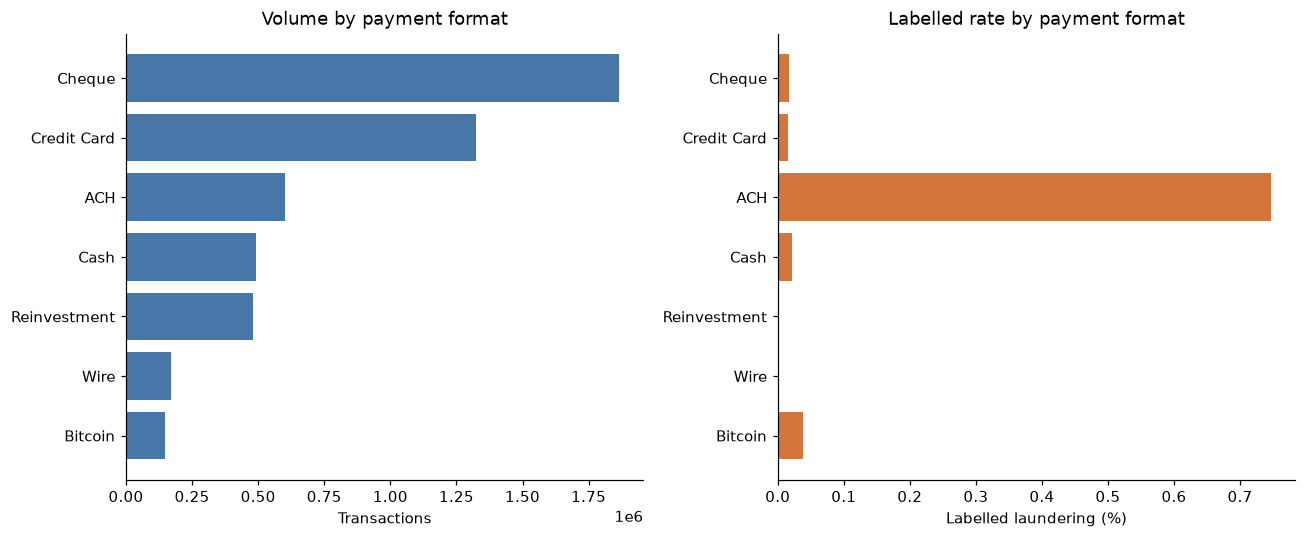

payment_format  transactions  labelled  labelled_pct
           ACH        600797    4483.0      0.746175
       Bitcoin        146091      56.0      0.038332
          Cash        490891     108.0      0.022001
        Cheque       1864331     324.0      0.017379
   Credit Card       1323324     206.0      0.015567
          Wire        171855       0.0      0.000000
  Reinvestment        481056       0.0      0.000000


In [4]:
formats = query('''
SELECT payment_format, COUNT(*) AS transactions, SUM(is_laundering) AS labelled,
       AVG(is_laundering)*100 AS labelled_pct
FROM transactions GROUP BY 1 ORDER BY transactions
''')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(formats.payment_format, formats.transactions, color="#4776a8")
axes[0].set_xlabel("Transactions")
axes[0].set_title("Volume by payment format")
axes[1].barh(formats.payment_format, formats.labelled_pct, color="#d4753b")
axes[1].set_xlabel("Labelled laundering (%)")
axes[1].set_title("Labelled rate by payment format")
fig.tight_layout()
plt.show()
print(formats.sort_values("labelled_pct", ascending=False).to_string(index=False))


## 4. Amount distributions, separated by currency
The three most frequent payment currencies are shown. Each line uses all rows
within that currency and label. Logarithmic amount bins accommodate large values;
normalizing each class separately makes shape differences visible despite
imbalance. The transformed x-axis is log10(1 + amount in that currency).


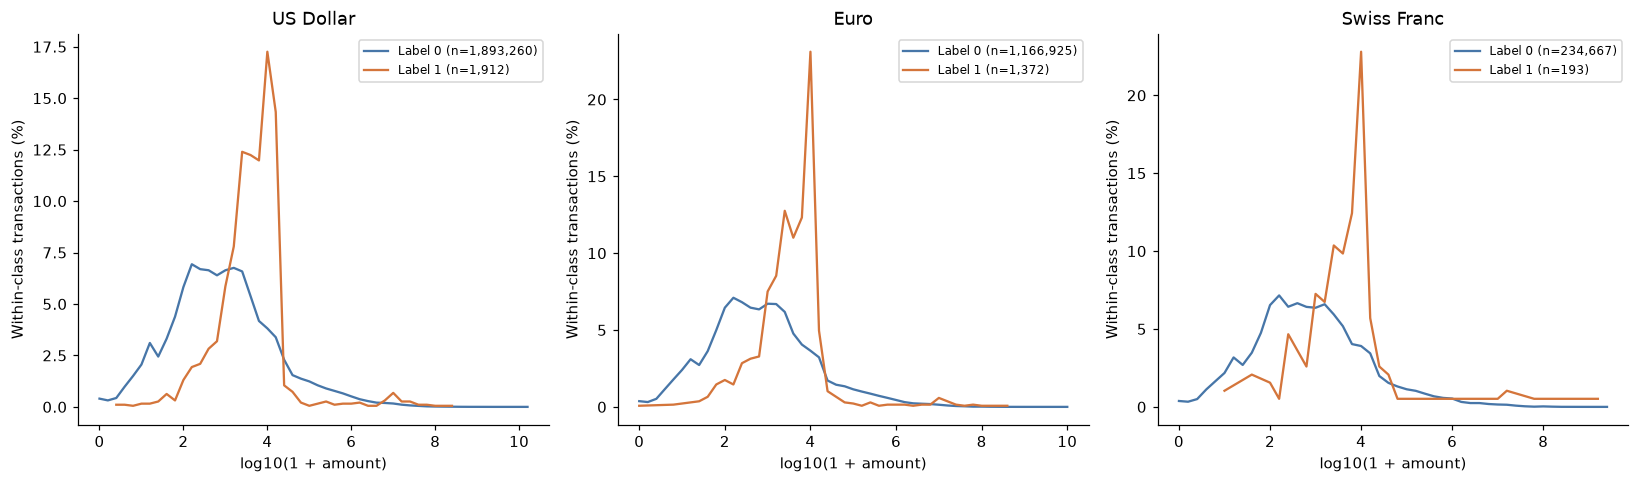

In [5]:
currencies = query('''
SELECT payment_currency, COUNT(*) AS n FROM transactions
GROUP BY 1 ORDER BY n DESC LIMIT 3
''').payment_currency.tolist()
fig, axes = plt.subplots(1, len(currencies), figsize=(15, 4.5), squeeze=False)
for ax, currency in zip(axes[0], currencies):
    hist = con.execute('''
        SELECT is_laundering, FLOOR(LOG10(1+amount_paid)*5)/5 AS bin,
               COUNT(*) AS n
        FROM transactions WHERE payment_currency = ?
        GROUP BY 1, 2 ORDER BY 2
    ''', [currency]).fetchdf()
    for label, color in [(0, "#4776a8"), (1, "#d4753b")]:
        sub = hist[hist.is_laundering == label]
        if len(sub):
            ax.plot(sub.bin, sub.n/sub.n.sum()*100, color=color,
                    label=f"Label {label} (n={sub.n.sum():,})")
    ax.set_title(currency)
    ax.set_xlabel("log10(1 + amount)")
    ax.set_ylabel("Within-class transactions (%)")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5. Time of day and transfer characteristics
Hours use the dataset's recorded clock; no timezone conversion is assumed.
Cross-bank and currency-mismatch groups describe associations, not causes.


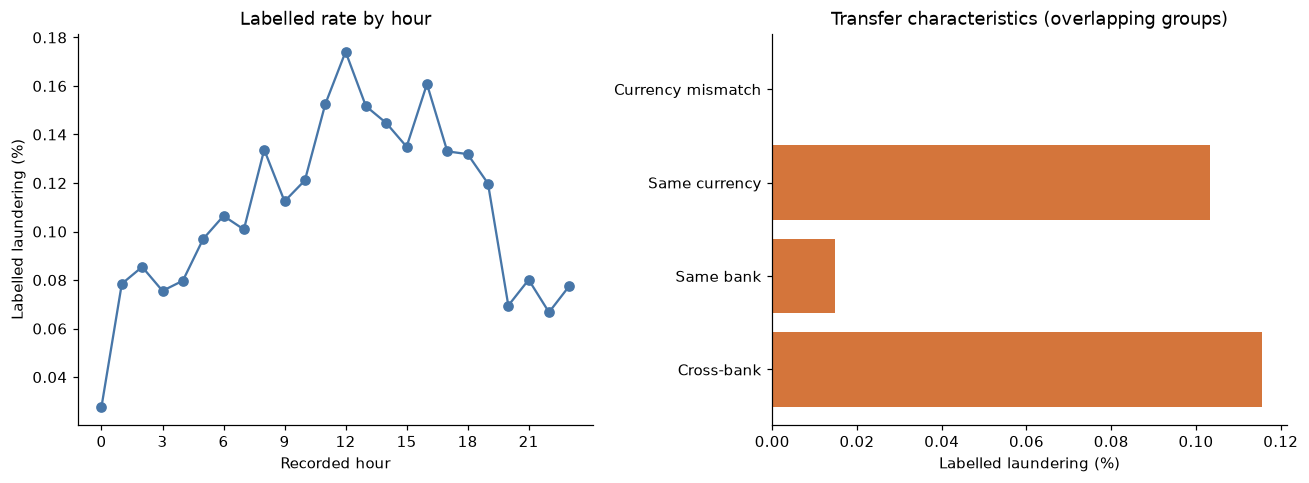

       group_name  transactions  labelled_pct
       Cross-bank       4387090      0.115658
        Same bank        691255      0.014900
    Same currency       5006175      0.103412
Currency mismatch         72170      0.000000


In [6]:
hourly = query('''
SELECT EXTRACT(hour FROM timestamp) AS hour, COUNT(*) AS transactions,
       AVG(is_laundering)*100 AS labelled_pct
FROM transactions GROUP BY 1 ORDER BY 1
''')
characteristics = query('''
SELECT CASE WHEN from_bank <> to_bank THEN 'Cross-bank' ELSE 'Same bank' END AS group_name,
       COUNT(*) AS transactions, AVG(is_laundering)*100 AS labelled_pct
FROM transactions GROUP BY 1
UNION ALL
SELECT CASE WHEN payment_currency <> receiving_currency THEN 'Currency mismatch'
            ELSE 'Same currency' END,
       COUNT(*), AVG(is_laundering)*100
FROM transactions GROUP BY 1
''')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(hourly.hour, hourly.labelled_pct, marker="o", color="#4776a8")
axes[0].set_xlabel("Recorded hour")
axes[0].set_ylabel("Labelled laundering (%)")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_title("Labelled rate by hour")
axes[1].barh(characteristics.group_name, characteristics.labelled_pct, color="#d4753b")
axes[1].set_xlabel("Labelled laundering (%)")
axes[1].set_title("Transfer characteristics (overlapping groups)")
fig.tight_layout()
plt.show()
print(characteristics.to_string(index=False))


## 6. Sending-account activity
Account counts span the full observed period. Logarithmic bins show both occasional
and very active accounts. These retrospective totals must not be used directly as
historical model features.


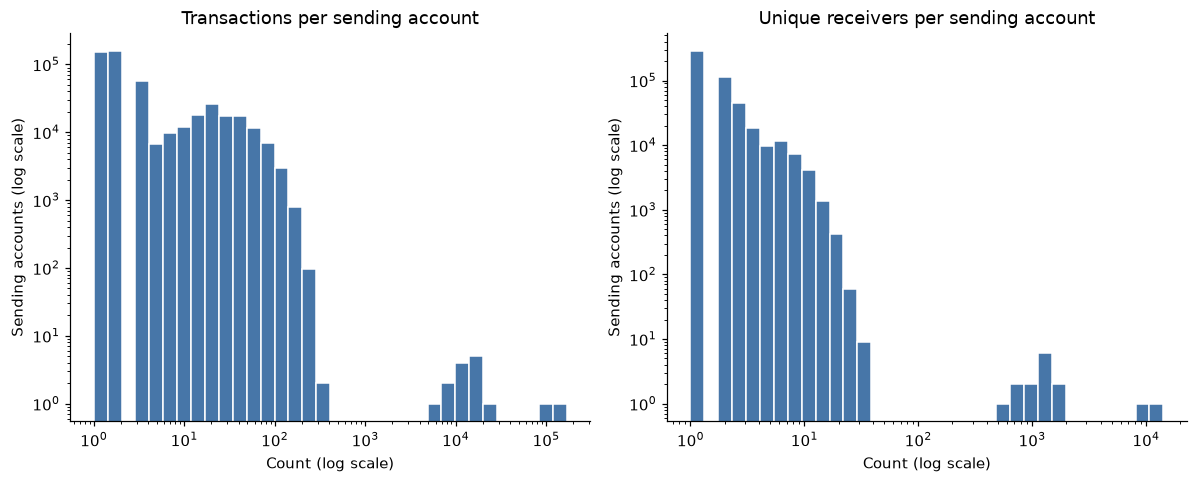

        transactions  counterparties
count  496999.000000   496999.000000
mean       10.218019        2.043739
std       290.282946       24.630535
min         1.000000        1.000000
50%         2.000000        1.000000
90%        29.000000        4.000000
99%        92.000000       10.000000
max    168672.000000    14230.000000


In [7]:
accounts = query('''
SELECT sender_id, COUNT(*) AS transactions,
       COUNT(DISTINCT receiver_id) AS counterparties
FROM transactions GROUP BY 1
''')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, column, title in zip(axes, ["transactions", "counterparties"],
                           ["Transactions per sending account", "Unique receivers per sending account"]):
    upper = max(2, int(accounts[column].max()))
    bins = np.unique(np.geomspace(1, upper+1, 35))
    ax.hist(accounts[column], bins=bins, color="#4776a8", edgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Count (log scale)")
    ax.set_ylabel("Sending accounts (log scale)")
fig.tight_layout()
plt.show()
print(accounts[["transactions", "counterparties"]].describe(percentiles=[.5,.9,.99]).to_string())


## Interpretation and limits
- Laundering labels are rare; compare precision/recall and workload, not accuracy.
- Amount distributions must be compared within currencies.
- Payment-format and time patterns are descriptive associations in synthetic data.
- Aggregate patterns can reflect the observation window and group sample sizes.
- This notebook validates and describes the full input; it does not change trained
  models or their operating threshold.


In [8]:
con.close()
print("EDA completed. All six figures use the full IBM input through aggregation.")


EDA completed. All six figures use the full IBM input through aggregation.
